# Simple Linear Regression — Salary vs. Experience

Predicting `Salary` from `YearsExperience` with a single-feature linear model $\hat{y} = \beta_0 + \beta_1 x$, fit by minimizing SSE.

In [35]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [36]:
df=pd.read_csv('Salary_dataset.csv')

Dataset: `YearsExperience` (feature) and `Salary` (target), 30 rows.

In [37]:
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


## EDA

`describe()` for scale/spread, `corr()` for linear strength before fitting anything.

In [38]:
df.describe()

,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


In [39]:
df.corr()

,Unnamed: 0,YearsExperience,Salary
Unnamed: 0,1.000000,0.986460,0.960826
YearsExperience,0.986460,1.000000,0.978242
Salary,0.960826,0.978242,1.000000


$r \approx 0.98$ between `YearsExperience` and `Salary` — a strong linear relationship, so a linear model is a reasonable fit.

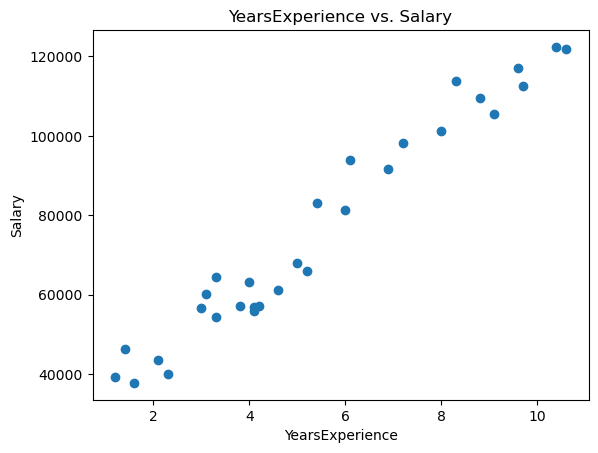

In [40]:
plt.scatter(df["YearsExperience"], df["Salary"])

plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.title("YearsExperience vs. Salary")
plt.show()

Scatter confirms it: points trace a line, not a curve — visual backup for the correlation above.

In [41]:
X=df[['YearsExperience']]
y=df['Salary']

`X` stays 2D (`df[['YearsExperience']]`), `y` is 1D — the shape sklearn expects.

In [42]:
X

,YearsExperience
0,1.2
1,1.4
2,1.6
3,2.1
4,2.3
5,3.0
6,3.1
7,3.3
8,3.3
9,3.8


In [43]:
y

0      39344.0
1      46206.0
2      37732.0
3      43526.0
4      39892.0
5      56643.0
6      60151.0
7      54446.0
8      64446.0
9      57190.0
10     63219.0
11     55795.0
12     56958.0
13     57082.0
14     61112.0
15     67939.0
16     66030.0
17     83089.0
18     81364.0
19     93941.0
20     91739.0
21     98274.0
22    101303.0
23    113813.0
24    109432.0
25    105583.0
26    116970.0
27    112636.0
28    122392.0
29    121873.0
Name: Salary, dtype: float64

In [44]:
X.shape

(30, 1)

In [45]:
y.shape

(30,)

## Train/test split

20% held out (`test_size=0.20`) to evaluate on unseen data; `random_state=42` for reproducibility.

In [46]:
from sklearn.model_selection import train_test_split

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

## Scaling

`StandardScaler` z-scores each value using the *training* mean/std, then applies that same transform to the test data — fit on train only, to avoid leakage.

In [48]:
from sklearn.preprocessing import StandardScaler

In [49]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Scaling doesn't change the fit for single-feature OLS — just the units of the learned coefficient (see interpretation below).

In [50]:
X_train_scaled

array([[ 1.77445774],
       [ 1.21912622],
       [-0.41216011],
       [-1.41869849],
       [-1.03690807],
       [-0.03036969],
       [-0.79395053],
       [-0.37745189],
       [-0.41216011],
       [ 0.94146047],
       [-1.34928205],
       [-1.27986561],
       [ 1.32325088],
       [-1.10632451],
       [ 0.66379471],
       [ 1.49679198],
       [ 0.24729607],
       [ 1.84387418],
       [ 0.55967005],
       [-0.68982587],
       [-0.44686833],
       [-0.23861901],
       [ 0.28200429],
       [-0.75924231]])

In [51]:
X_test_scaled

array([[ 1.5315002 ],
       [-0.09978613],
       [ 1.04558513],
       [ 0.03904675],
       [-0.68982587],
       [-0.51628477]])

## Fitting the model

`model.fit()` solves the normal equation $\beta = (X^TX)^{-1}X^Ty$ for $\beta_0, \beta_1$.

In [52]:
from sklearn.linear_model import LinearRegression

In [53]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

In [54]:
print(model.intercept_)

74208.625


In [55]:
print(model.coef_)

[27151.53742583]


Since `X` was scaled: `intercept_` is the predicted salary at the *mean* experience, and `coef_` is the salary change per **one std dev** of experience — not per year.

In [56]:
y_pred = model.predict(X_test_scaled)

## Evaluating on the test set

Compare `y_pred` to the true `y_test` via MAE, RMSE, and R².

In [57]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [58]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

In [59]:
mae

6286.453830757742

In [60]:
rmse

7059.043621901507

In [61]:
r2

0.9024461774180498

MAE ≈ \$6.3k average error; RMSE ≈ \$7.1k (close to MAE, so no wild outliers); R² ≈ 0.90 — experience explains ~90% of salary variance in the test set.

In [68]:
a=scaler.transform([[1.2]])
b=model.predict(a)
print(b)

[35688.77986711]


e:\anaconda\envs\abdullah\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Quick sanity check: predicting salary for 1.2 years experience, which is within the training range.

In [72]:
new_exp = 1.4

# 1. Reshape into 2D (1 sample, 1 feature) and scale with the fitted scaler
new_exp_scaled = scaler.transform(np.array([[new_exp]]))

# 2. Predict height and grab the single value ([0])
pred_salary = model.predict(new_exp_scaled)[0]
print(pred_salary)

37573.54293171708


e:\anaconda\envs\abdullah\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


New inputs must go through the fitted `scaler` before `model.predict()` — same transform as training, never raw.